In [1]:
import time
start_time=time.time()

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
# Add path to py_modules 
sys.path.append(str(Path().resolve().parents[0] / 'py_modules')) # 1 level up = project root

# Add path to pipeline_config.py
sys.path.append(str(Path().resolve().parents[0]))  # 1 level up = project root

# Import from pipeline_config and py_modules
from pipeline_config import OBSERVATIONS_DIR, MAPS_DIR, FIGS_DIR

In [12]:
with fits.open('Halpha_moment0.fits') as hdul:
    n = None
    sb = hdul[0].data[:n, :n].astype(np.float64)
    hdul.info()

sb /= sb.max()


Filename: Halpha_moment0.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     172   (697, 689)   float64   


In [13]:
with fits.open('Halpha_moment1.fits') as hdul:
    n = None
    vv = hdul[0].data[:n, :n].astype(np.float64)
    hdul.info()

Filename: Halpha_moment1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     175   (697, 689)   float64   


In [24]:
name_export = "SAMFP-Dor-H"

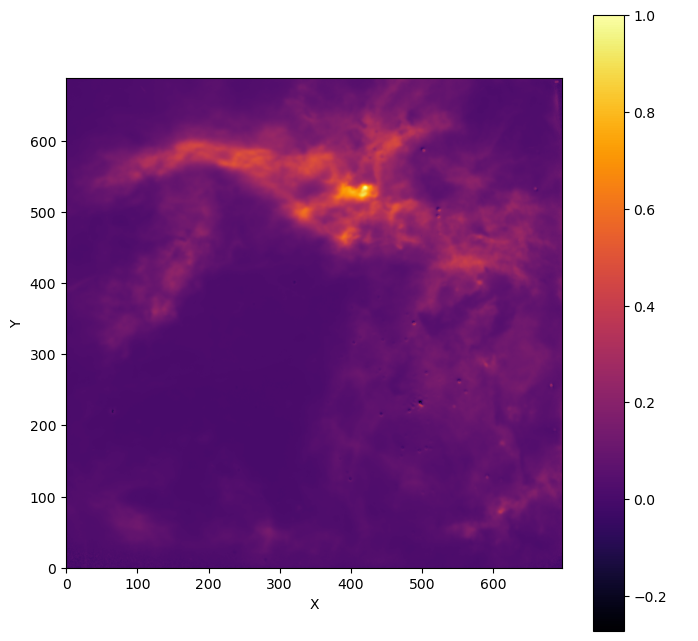

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(sb, cmap='inferno')

cbar = plt.colorbar()
#plt.clim(0.001,1)
cbar.set_label(' ', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

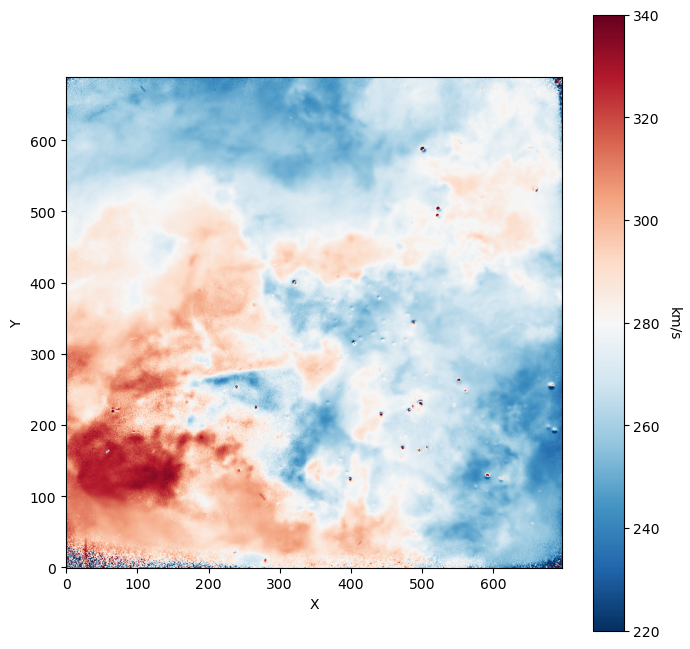

In [15]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(vv, cmap='RdBu_r')

cbar = plt.colorbar()
plt.clim(220,340)
cbar.set_label('km/s', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

In [18]:
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
import astropy.units as u
c0 = SkyCoord.from_name("Tarantula")
c0

<SkyCoord (ICRS): (ra, dec) in deg
    (84.675, -69.1)>

In [19]:
# MUSE image array

# Array shape
ny, nx = sb.shape

# MUSE pixel scale
pixscale_arcsec = 0.18
pixscale_deg = pixscale_arcsec / 3600.0

# Approximate image center in sky coordinates
#ra0 = 84.675
#dec0 = -69.1

# Create WCS object
wcs_samfp = WCS(naxis=2)

wcs_samfp.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs_samfp.wcs.crval = [84.6975, -69.0953]

# FITS/WCS uses 1-based reference pixels
wcs_samfp.wcs.crpix = [nx  / 2, ny / 2]

# RA axis usually has negative pixel scale
wcs_samfp.wcs.cdelt = [-pixscale_deg, pixscale_deg]

wcs_samfp

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN' 
CRVAL : 84.6975 -69.0953 
CRPIX : 348.5 344.5 
PC1_1 PC1_2  : 1.0 0.0 
PC2_1 PC2_2  : 0.0 1.0 
CDELT : -4.9999999999999996e-05 4.9999999999999996e-05 
NAXIS : 0  0

C:\Users\javas\AppData\Local\Temp\ipykernel_34088\3249490861.py:6: RuntimeWarning: invalid value encountered in log10
  np.log10(sb),


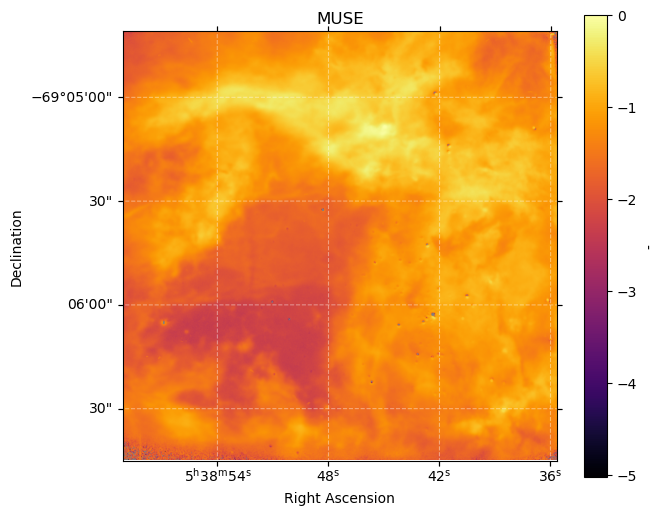

In [20]:
fig = plt.figure(figsize=(7, 6))

ax = fig.add_subplot(1, 1, 1, projection=wcs_samfp)

im = ax.imshow(
    np.log10(sb),
    origin="lower",
    cmap="inferno",
   # vmin=220,
   # vmax=340,
)

plt.colorbar(im, ax=ax, label="-")

ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.set_title("MUSE")

ax.grid(color="white", alpha=0.4, linestyle="--")
im.cmap.set_bad(color='gray')

plt.show()

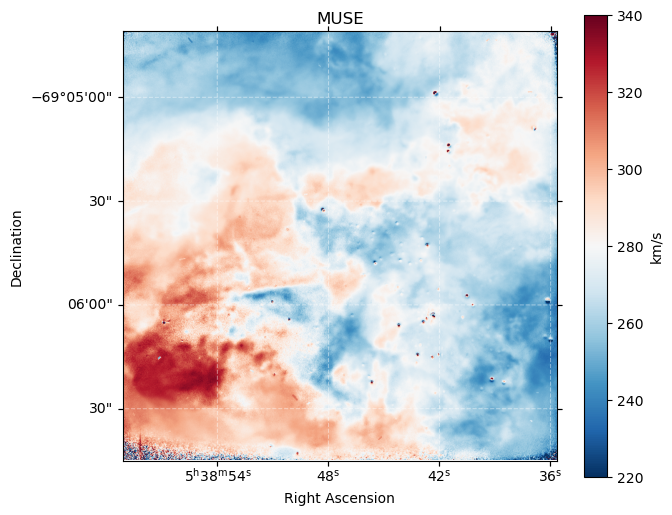

In [22]:
fig = plt.figure(figsize=(7, 6))

ax = fig.add_subplot(1, 1, 1, projection=wcs_samfp)

im = ax.imshow(
    vv,
    origin="lower",
    cmap="RdBu_r",
    vmin=220,
    vmax=340,
)


plt.colorbar(im, ax=ax, label="km/s")

ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.set_title("MUSE")

ax.grid(color="white", alpha=0.4, linestyle="--")
im.cmap.set_bad(color='gray')

plt.show()

C:\Users\javas\AppData\Local\Temp\ipykernel_34088\795274659.py:14: RuntimeWarning: invalid value encountered in log10
  np.log10(sb),


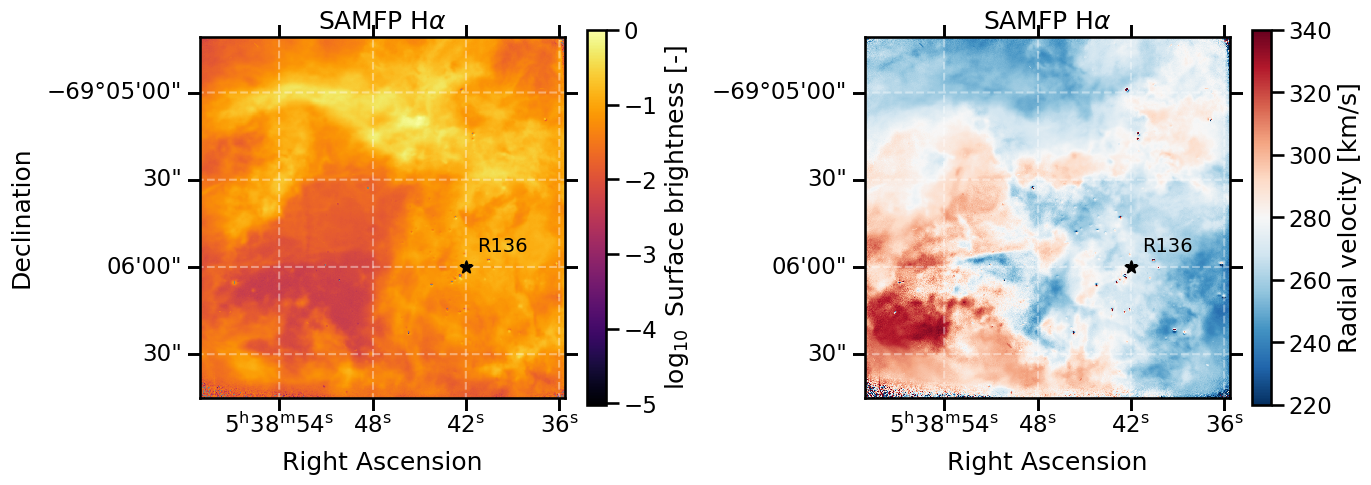

In [26]:
sns.set_context("talk")


fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    subplot_kw={"projection": wcs_samfp}
)

# -------------------------------------------------------
# Left panel: Surface brightness
# -------------------------------------------------------
im1 = ax1.imshow(
    np.log10(sb),
    origin="lower",
    cmap="inferno",
    interpolation="nearest"
)

cbar1 = fig.colorbar(
    im1,
    ax=ax1,
    label=r"$\log_{10}$ Surface brightness [-]",
    shrink=0.8
)

ax1.set_xlabel("Right Ascension")
ax1.set_ylabel("Declination")
ax1.set_title(r"SAMFP H$\alpha$")

ax1.grid(
    color="white",
    alpha=0.4,
    linestyle="--"
)

# R136 position
ax1.scatter(
    c0.ra.deg,
    c0.dec.deg,
    transform=ax1.get_transform("world"),
    color="black",
    s=80,
    marker="*",
    zorder=5
)

ax1.annotate(
    "R136",
    xy=(c0.ra.deg, c0.dec.deg),
    xycoords=ax1.get_transform("world"),
    xytext=(8, 8),
    textcoords="offset points",
    color="black",
    fontsize=14,
    ha="left",
    va="bottom"
)

im1.cmap.set_bad(color="gray")


# -------------------------------------------------------
# Right panel: Radial velocity
# -------------------------------------------------------
im2 = ax2.imshow(
    vv,
    origin="lower",
    cmap="RdBu_r",
    vmin=220,
    vmax=340,
    interpolation="nearest"
)

cbar2 = fig.colorbar(
    im2,
    ax=ax2,
    label="Radial velocity [km/s]",
    shrink=0.8
)

ax2.set_xlabel("Right Ascension")
ax2.set_ylabel("")
ax2.set_title(r"SAMFP H$\alpha$")

ax2.grid(
    color="white",
    alpha=0.4,
    linestyle="--"
)

# R136 position
ax2.scatter(
    c0.ra.deg,
    c0.dec.deg,
    transform=ax2.get_transform("world"),
    color="black",
    s=80,
    marker="*",
    zorder=5
)

ax2.annotate(
    "R136",
    xy=(c0.ra.deg, c0.dec.deg),
    xycoords=ax2.get_transform("world"),
    xytext=(8, 8),
    textcoords="offset points",
    color="black",
    fontsize=14,
    ha="left",
    va="bottom"
)

im2.cmap.set_bad(color="gray")


# -------------------------------------------------------
# Layout
# -------------------------------------------------------
plt.tight_layout()

plt.savefig(FIGS_DIR / f"{name_export}.pdf", 
            dpi=300, 
bbox_inches='tight')

plt.show()

In [27]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 9717.641252994537 seconds ---
